# Convolutional Neural Networks and Pretrained Models

## Understanding Convolutional Neural Networks (CNNs)
A Convolutional Neural Network is a deep learning architecture designed to process grid-like data, particularly images.

CNNs automatically learn visual features instead of requiring humans to manually define every feature.

For example, when recognising a cat, a CNN may learn:

- Early layers: Edges and simple lines.

- Middle layers: Shapes, textures and patterns.

- Deeper layers: Eyes, ears and other complex structures.

- Final layers: Features useful for recognising the cat category.

<img src="img/cnn.png" alt="Convolutional Neural Networks" width="500">

## Main CNN components
1. Convolutional layer

Extracts visual features using filters (also called kernels).

A filter moves across the image and detects patterns such as edges and textures.

2. Activation function

Introduces non-linearity into the network.

- A commonly used activation function is ReLU:
$$
ReLU(x)=\max(0,x)
$$

It converts negative values to zero and keeps positive values.

3. Pooling layer

Reduces the spatial dimensions of feature maps.

- For example, max pooling selects the maximum value within a local region.

- This reduces computational requirements while retaining important features.

4. Fully connected layer

Combines the extracted features to make a prediction.

5. Softmax activation

Converts the final outputs into class probabilities.

For example:

$$
[2.0,1.0,0.5]
$$

becomes a probability distribution across the possible classes.

<img src="img/cnn_processes_image.png" alt="Convolutional Neural Networks" width="500">

## Pretrained Models
Training a deep learning model from scratch requires:

- Large amounts of labelled data.

- Significant computational resources.

- Time for training and experimentation.

A pretrained model is a model that has already been trained on a large dataset.

- `ImageNet` as an example.

ImageNet contains millions of images across many object categories.

* Rather than starting from zero, we can reuse the knowledge learned by an existing model.

Examples of pretrained models available through Keras include:

- ResNet50.

- VGG16.

- MobileNetV2.

- EfficientNet.

- InceptionV3.

**Why use pretrained models?**

Imagine you want to build an application that identifies different animals.

Instead of collecting millions of images and training a new CNN, you can use a model that has already learned to recognise common visual patterns.

You can then adapt it to your specific task.

Benefits:
1. Less training data may be required.

2. Training is usually faster.

3. Lower computational requirements.

4. Often better performance when the available dataset is small.

## Understanding Explainability in Neural Networks

A neural network can make accurate predictions, but understanding why it made a particular prediction is equally important.

This is the problem of explainability.

For example, if a model identifies an image as an elephant, we may want to know:

- Did it recognise the trunk?

- Did it focus on the ears?

- Did it focus on the body?

- Did it use irrelevant background information?

**Two Techniques:**

1. Feature activation maps.

2. Grad-CAM.

### Feature activation maps
A CNN learns different visual patterns at different layers.

Early layers may respond to:

- Edges.

- Lines.

- Corners.

- Simple textures.

Deeper layers may respond to:

- Complex shapes.

- Object parts.

- More meaningful visual structures.

An activation map shows which spatial regions produce stronger responses in a particular layer.

##### Practical implementation: VGG16 feature activations

- VGG16 is another pretrained CNN architecture.

In [14]:
## load the model:
import keras

from keras.applications.resnet50 import ResNet50
from keras.applications.vgg16 import (
    VGG16,
    decode_predictions,
    preprocess_input
)

model = VGG16(
    weights='imagenet',
    include_top=False
)



import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

Understanding the parameters:

- `weights='imagenet'`: Uses pretrained ImageNet weights.

- `include_top=False`: Removes the final classification layers.

We only want the convolutional feature extractor.

Load and preprocess the image:

In [3]:
img_path = 'data/elephant.jpg'

img = keras.utils.load_img(
    img_path,
    target_size=(224, 224)
)

x = keras.utils.img_to_array(img)
x = np.expand_dims(x, axis=0)

x = preprocess_input(x)

In [4]:
### Extract the features:

features = model.predict(x)

activation = features[0].mean(axis=-1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


In [5]:
### The operation:

features[0].mean(axis=-1)

array([[ 0.66580683,  0.47238964,  0.33321837,  0.29422897,  0.40979075,
         0.3880974 ,  0.5217414 ],
       [ 0.7607498 ,  0.78375643,  1.2396101 ,  0.73853433,  0.5434237 ,
         0.31920403,  0.38779247],
       [ 1.6174169 ,  4.094492  ,  8.496698  ,  6.3532877 ,  5.431916  ,
         3.3506355 ,  1.2428503 ],
       [ 1.8283851 ,  6.857071  , 11.918272  , 10.368932  ,  9.2854805 ,
         5.0683727 ,  1.6558414 ],
       [ 1.5001094 ,  3.3001297 ,  4.121214  ,  6.941767  ,  5.3232555 ,
         1.7329797 ,  0.9183997 ],
       [ 1.1880331 ,  1.9510318 ,  1.9761063 ,  3.8831758 ,  3.2924318 ,
         1.0839989 ,  0.7268141 ],
       [ 1.3803209 ,  1.0290928 ,  1.101682  ,  1.728512  ,  1.0246696 ,
         0.9848199 ,  1.050298  ]], dtype=float32)

calculates the average activation across the feature channels.

This produces a two-dimensional spatial representation of the activations.

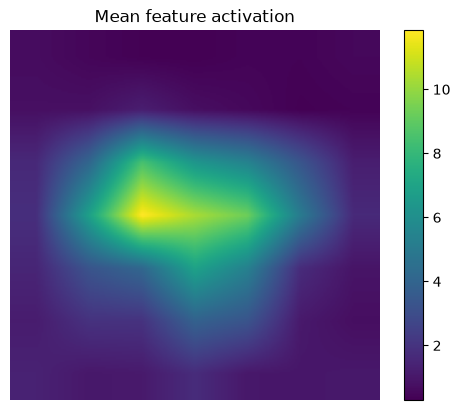

In [6]:
#### Resize and visualise:

from tensorflow.image import resize

heatmap_big = resize(
    activation[..., np.newaxis],
    (224, 224)
).numpy().squeeze()

plt.imshow(heatmap_big, cmap='viridis')
plt.colorbar()
plt.title('Mean feature activation')
plt.axis('off')
plt.show()

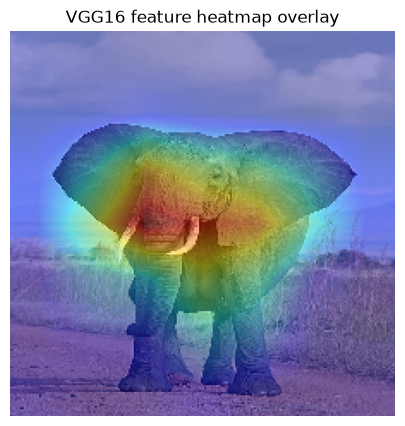

In [7]:
#### Overlay the heatmap:
plt.figure(figsize=(5, 5))

plt.imshow(img)

plt.imshow(
    heatmap_big,
    cmap='jet',
    alpha=0.4
)

plt.axis('off')
plt.title('VGG16 feature heatmap overlay')

plt.show()

How to interpret the result:

- Brighter regions indicate stronger average activations.

- Darker regions indicate weaker average activations.

- The heatmap reveals where the selected feature maps respond strongly.

Note that averaging all channels is a simplified visualisation, not a complete explanation of the model's decision.

### Grad-CAM (Gradient-weighted Class Activation Mapping)

Grad-CAM is a visual explanation technique that identifies image regions that contribute to a particular class prediction.

_For example_: 

if ResNet50 predicts an elephant, Grad-CAM produces a heatmap highlighting the regions that support that prediction.

In [12]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras import layers, models

base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

x = layers.GlobalAveragePooling2D()(base_model.output)
output = layers.Dense(7, activation="softmax")(x)

model = models.Model(
    inputs=base_model.input,
    outputs=output
)

In [15]:
last_conv_layer = "block5_conv3"

grad_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer(last_conv_layer).output,
        model.output
    ]
)

In [19]:
with tf.GradientTape() as tape:

    conv_outputs, predictions = grad_model(
        img_array,
        training=False
    )

    predicted_class = tf.argmax(
        predictions[0]
    )

    class_score = predictions[:, predicted_class]

grads = tape.gradient(class_score, conv_outputs)

weights = tf.reduce_mean(
    grads,
    axis=(0, 1, 2)
)

conv_outputs = conv_outputs[0]

heatmap = tf.reduce_sum(
    conv_outputs * weights,
    axis=-1
)

heatmap = tf.maximum(heatmap, 0)

heatmap /= tf.reduce_max(heatmap) + 1e-10

heatmap = heatmap.numpy()

NameError: name 'img_array' is not defined

**Feature activation vs Grad-CAM**
| Feature | Feature activation | Grad-CAM |
| --- | --- | --- |
| Main purpose | Visualise layer responses | Explain a particular class prediction |
| Uses gradients | Not necessarily | Yes |
| Class-specific | Not necessarily | Yes |
| Output | Activation map | Class-discriminative heatmap |
| Application | Understand learned features | Interpret predictions |

**Important takeaway**: 

Explainability helps us understand whether a model is focusing on meaningful visual information or potentially misleading features.